## Intro

This was a small project to put some of the techniques learnt through my Data science course into practice on public cricket data from Cricsheet (big thanks to them for their excellent website). 

## Data loading and exploration

### Installs and loads

In [27]:
# 1. Force install the specific Pandas version this was written with
!pip install pandas==2.2.3


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
from pathlib import Path

# Works when notebook is run from the project root
# or from the notebooks folder
cwd = Path.cwd()

if (cwd / "notebooks").is_dir() and (cwd / "data").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "notebooks").is_dir() and (cwd.parent / "data").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        f"Cannot locate project root from {cwd}"
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "cricsheet_json"
REFERENCE_DIR = DATA_DIR / "reference"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Project root:", PROJECT_ROOT)
print("Raw data exists:", RAW_DIR.exists())

Project root: c:\Users\scott\OneDrive\Documents\My Stuff\Cricket\Data projects\my-data-science-project
Raw data exists: True


In [52]:
# Further imports and data load from web source

import os
import urllib.request
import zipfile
import json
import pandas as pd
from tqdm import tqdm

# Define paths
url = 'https://cricsheet.org/downloads/all_json.zip'

zip_path = PROJECT_ROOT / 'data' / 'raw' / 'all_json.zip'
extract_dir = RAW_DIR  # data/raw/cricsheet_json/

# Create directory if needed
extract_dir.mkdir(parents=True, exist_ok=True)

# Check whether data has already been downloaded
json_files = list(extract_dir.glob('*.json'))

if json_files:
    print(f"Cricsheet data already exists: {len(json_files):,} JSON files.")
    print("Skipping download and extraction.")

else:
    print("Downloading Cricsheet data...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete.")

    print("Extracting files...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    print(f"Extracted files to {extract_dir}")

    # Remove ZIP after successful extraction
    zip_path.unlink()

print(f"Data directory: {extract_dir}")


Cricsheet data already exists: 23,132 JSON files.
Skipping download and extraction.
Data directory: c:\Users\scott\OneDrive\Documents\My Stuff\Cricket\Data projects\my-data-science-project\data\raw\cricsheet_json


In [29]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Files in directory:", list(Path.cwd().iterdir()))

Current directory: c:\Users\scott\OneDrive\Documents\My Stuff\Cricket\Data projects\my-data-science-project\notebooks
Files in directory: [WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/notebooks/all_json.zip'), WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/notebooks/Cricket_project.ipynb'), WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/notebooks/Cricket_project_old.ipynb'), WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/notebooks/cricsheet_json')]


In [30]:
# Additional data load from other reference data stored on the project path

from pathlib import Path
import pandas as pd

# Assumes VS Code runs the notebook from the project root
from pathlib import Path

if (Path.cwd() / "data").is_dir():
    DATA_DIR = Path.cwd() / "data"
elif (Path.cwd().parent / "data").is_dir():
    DATA_DIR = Path.cwd().parent / "data"
else:
    raise FileNotFoundError("Cannot locate the data folder")

print("Using data directory:", DATA_DIR)
print("Available files:", list(DATA_DIR.iterdir()))

df_gdrive_venues= pd.read_csv(DATA_DIR / "cricket_venues_full_with_playing_nation.csv")
df_gdrive_venues_old = pd.read_csv(DATA_DIR / "cricket_venues_with_playing_nation.csv")

Using data directory: c:\Users\scott\OneDrive\Documents\My Stuff\Cricket\Data projects\my-data-science-project\data
Available files: [WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/data/cricket_venues_full_with_playing_nation.csv'), WindowsPath('c:/Users/scott/OneDrive/Documents/My Stuff/Cricket/Data projects/my-data-science-project/data/cricket_venues_with_playing_nation.csv')]


### Initial data inspection and transformation

In [31]:
# 3. Load a sample JSON file to understand the structure
json_files = [f for f in os.listdir(extract_dir) if f.endswith('.json')]
print(f"Total JSON files extracted: {len(json_files)}")

if json_files:
    sample_file_path = os.path.join(extract_dir, json_files[0])
    with open(sample_file_path, 'r') as f:
        sample_data = json.load(f)

    # Display basic info of the sample JSON
    print("\nSample Match Info Keys:")
    print(sample_data.get('info', {}).keys())
else:
    print("No JSON files found.")


Total JSON files extracted: 23132

Sample Match Info Keys:
dict_keys(['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'match_type_number', 'officials', 'outcome', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue'])


In [32]:
# 4. Parse multiple matches into a single flat pandas DataFrame
# (Extracting basic match metadata as an example)
match_list = []

# Let's load the first 100 matches to keep it fast, or remove the slice to load all
max_matches_to_load = 100

print(f"Loading first {max_matches_to_load} matches into a DataFrame...")
for filename in tqdm(json_files[:max_matches_to_load]):
    file_path = os.path.join(extract_dir, filename)
    with open(file_path, 'r') as f:
        data = json.load(f)
        info = data.get('info', {})

        # Extract some common fields safely
        match_details = {
            'match_id': filename.replace('.json', ''),
            'city': info.get('city'),
            'date': info.get('dates', [None])[0] if info.get('dates') else None,
            'gender': info.get('gender'),
            'match_type': info.get('match_type'),
            'outcome_winner': info.get('outcome', {}).get('winner'),
            'venue': info.get('venue'),
            'team1': info.get('teams', [None, None])[0] if len(info.get('teams', [])) > 0 else None,
            'team2': info.get('teams', [None, None])[1] if len(info.get('teams', [])) > 1 else None
        }
        match_list.append(match_details)

df_matches = pd.DataFrame(match_list)
display(df_matches.head())


Loading first 100 matches into a DataFrame...


100%|██████████| 100/100 [00:01<00:00, 59.17it/s]


,match_id,city,date,gender,match_type,outcome_winner,venue,team1,team2
0,1000851,Perth,2016-11-03,male,Test,South Africa,Western Australia Cricket Association Ground,Australia,South Africa
1,1000853,Hobart,2016-11-12,male,Test,South Africa,Bellerive Oval,Australia,South Africa
2,1000855,None,2016-11-24,male,Test,Australia,Adelaide Oval,Australia,South Africa
3,1000881,Brisbane,2016-12-15,male,Test,Australia,"Brisbane Cricket Ground, Woolloongabba",Australia,Pakistan
4,1000883,None,2016-12-26,male,Test,Australia,Melbourne Cricket Ground,Australia,Pakistan


### Inspecting Ball-by-Ball Data
Below we will write a function to load a single match's JSON file and parse its detailed ball-by-ball deliveries from the `innings` field into a structured pandas DataFrame.

In [33]:
def parse_match_to_dataframe(match_data, match_id, country_map=None, nation_map=None):
    """
    Consolidated, single-source-of-truth helper to parse a Cricsheet match JSON dict
    into a flat list of ball-by-ball dictionaries.
    """
    deliveries_list = []
    info = match_data.get('info', {})
    teams = info.get('teams', [])
    match_type = info.get('match_type', 'Unknown')
    venue = info.get('venue', 'Unknown')

    # Resolve venue country and playing nation
    venue_country = 'Unknown'
    playing_nation = 'Unknown'

    def resolve_mapping(venue_name, mapping_dict):
        if not venue_name or pd.isna(venue_name) or not mapping_dict:
            return 'Unknown'
        val = str(venue_name).strip().lower()
        if val in mapping_dict:
            return mapping_dict[val]
        for key, value in mapping_dict.items():
            if key in val or val in key:
                return value
        return 'Unknown'

    if country_map and nation_map:
        venue_country = resolve_mapping(venue, country_map)
        playing_nation = resolve_mapping(venue, nation_map)

    # Extract country from match registry if still unknown
    if venue_country == 'Unknown':
        registry = info.get('registry', {})
        venue_country = registry.get('countries', {}).get(venue, 'Unknown')

    # Dynamic Opposing Team resolution
    for innings_idx, innings in enumerate(match_data.get('innings', [])):
        team_batting = innings.get('team')

        opposing_team = 'Unknown'
        if len(teams) == 2:
            opposing_team = teams[1] if teams[0] == team_batting else teams[0]
        elif len(teams) > 0:
            opposing_team = [t for t in teams if t != team_batting][0] if any(t != team_batting for t in teams) else 'Unknown'

        over_data = innings.get('overs', [])
        for over_item in over_data:
            over_num = over_item.get('over')
            deliveries = over_item.get('deliveries', [])

            for ball_idx, delivery in enumerate(deliveries):
                runs = delivery.get('runs', {})
                wickets = delivery.get('wickets', [])
                is_wicket = len(wickets) > 0

                ball_record = {
                    'match_id': match_id,
                    'innings_number': innings_idx + 1,
                    'batting_team': team_batting,
                    'opposing_team': opposing_team,
                    'over': over_num + 1,
                    'ball_of_over': ball_idx + 1,
                    'batter': delivery.get('batter'),
                    'bowler': delivery.get('bowler'),
                    'non_striker': delivery.get('non_striker'),
                    'batter_runs': runs.get('batter', 0),
                    'extras_runs': runs.get('extras', 0),
                    'total_runs': runs.get('total', 0),
                    'is_wicket': int(is_wicket),
                    'player_out': wickets[0].get('player_out') if is_wicket else None,
                    'dismissal_kind': wickets[0].get('kind') if is_wicket else None,
                    'match_type': match_type,
                    'venue': venue,
                    'venue_country': venue_country,
                    'playing_nation': playing_nation
                }
                deliveries_list.append(ball_record)

    return deliveries_list

# Quick sanity check utilizing the consolidated parser
sample_match_id = df_matches.iloc[0]['match_id']
print(f"Testing unified parser on Match ID: {sample_match_id}")
with open(os.path.join(extract_dir, f"{sample_match_id}.json"), 'r') as f:
    test_data = json.load(f)
sample_df = pd.DataFrame(parse_match_to_dataframe(test_data, sample_match_id))
display(sample_df.head())

Testing unified parser on Match ID: 1000851


,match_id,innings_number,batting_team,opposing_team,over,ball_of_over,batter,bowler,non_striker,batter_runs,extras_runs,total_runs,is_wicket,player_out,dismissal_kind,match_type,venue,venue_country,playing_nation
0,1000851,1,South Africa,Australia,1,1,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Unknown,Unknown
1,1000851,1,South Africa,Australia,1,2,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Unknown,Unknown
2,1000851,1,South Africa,Australia,1,3,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Unknown,Unknown
3,1000851,1,South Africa,Australia,1,4,SC Cook,MA Starc,D Elgar,0,0,0,1,SC Cook,caught,Test,Western Australia Cricket Association Ground,Unknown,Unknown
4,1000851,1,South Africa,Australia,1,5,HM Amla,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Unknown,Unknown


In [34]:
all_balls = []

# Prepare local reference mappings for clean lookups
df_gdrive_venues['name_clean'] = df_gdrive_venues['name'].str.strip().str.lower()
df_gdrive_venues_old['name_clean'] = df_gdrive_venues_old['name'].str.strip().str.lower()

country_map = dict(zip(df_gdrive_venues_old['name_clean'], df_gdrive_venues_old['country']))
nation_map = dict(zip(df_gdrive_venues_old['name_clean'], df_gdrive_venues_old['playing_nation']))

country_map.update(dict(zip(df_gdrive_venues['name_clean'], df_gdrive_venues['country'])))
nation_map.update(dict(zip(df_gdrive_venues['name_clean'], df_gdrive_venues['playing_nation'])))

print("Compiling all ball-by-ball records cleanly utilizing the unified parser helper...")
for filename in tqdm(json_files):
    match_id = filename.replace('.json', '')
    file_path = os.path.join(extract_dir, filename)

    with open(file_path, 'r') as f:
        match_data = json.load(f)

    # Parse via single-source-of-truth function
    match_balls = parse_match_to_dataframe(match_data, match_id, country_map, nation_map)
    all_balls.extend(match_balls)

df_balls = pd.DataFrame(all_balls)
print(f"Successfully parsed {len(df_balls)} balls from {len(json_files)} matches with correct metadata!")
display(df_balls.head())

Compiling all ball-by-ball records cleanly utilizing the unified parser helper...


100%|██████████| 23132/23132 [08:24<00:00, 45.84it/s]


Successfully parsed 11689170 balls from 23132 matches with correct metadata!


,match_id,innings_number,batting_team,opposing_team,over,ball_of_over,batter,bowler,non_striker,batter_runs,extras_runs,total_runs,is_wicket,player_out,dismissal_kind,match_type,venue,venue_country,playing_nation
0,1000851,1,South Africa,Australia,1,1,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
1,1000851,1,South Africa,Australia,1,2,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
2,1000851,1,South Africa,Australia,1,3,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
3,1000851,1,South Africa,Australia,1,4,SC Cook,MA Starc,D Elgar,0,0,0,1,SC Cook,caught,Test,Western Australia Cricket Association Ground,Australia,Australia
4,1000851,1,South Africa,Australia,1,5,HM Amla,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia


## Engineering and prep for modelling

### Feature Engineering & Preprocessing for XGBoost
We will preprocess the data for the XGBoost model. Our target variable will be predicting the total runs scored off the next ball (`total_runs`). We will encode categorical columns (like `batting_team`, `opposing_team`, `venue`, `venue_country`, `playing_nation`, `batter`, `bowler`) using target encoding or fast label encoding, and preserve numerical situation features like cumulative innings runs, wickets, and bowler metrics.

In [35]:
# Filter the main DataFrame to include only Test matches
df_tests = df_balls[df_balls['match_type'].str.lower() == 'test'].copy()

print(f"Total deliveries in Test matches: {len(df_tests)}")
print(f"Number of unique Test matches: {df_tests['match_id'].nunique()}")
display(df_tests.head())

Total deliveries in Test matches: 1771607
Number of unique Test matches: 920


,match_id,innings_number,batting_team,opposing_team,over,ball_of_over,batter,bowler,non_striker,batter_runs,extras_runs,total_runs,is_wicket,player_out,dismissal_kind,match_type,venue,venue_country,playing_nation
0,1000851,1,South Africa,Australia,1,1,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
1,1000851,1,South Africa,Australia,1,2,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
2,1000851,1,South Africa,Australia,1,3,SC Cook,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia
3,1000851,1,South Africa,Australia,1,4,SC Cook,MA Starc,D Elgar,0,0,0,1,SC Cook,caught,Test,Western Australia Cricket Association Ground,Australia,Australia
4,1000851,1,South Africa,Australia,1,5,HM Amla,MA Starc,D Elgar,0,0,0,0,None,None,Test,Western Australia Cricket Association Ground,Australia,Australia


In [36]:
print(pd.__version__)

2.2.3


In [37]:
import pandas as pd
import numpy as np

# Sort chronologically and create a clean copy before calculation
df_tests = df_tests.sort_values(by=['match_id', 'innings_number', 'over', 'ball_of_over']).copy()

def compute_delivery_intervals(group):
    # Sort to guarantee order inside the group
    group = group.sort_values(by=['over', 'ball_of_over'])

    since_wicket = []
    since_run = []
    since_boundary = []

    count_wicket = 0
    count_run = 0
    count_boundary = 0

    non_bowler_dismissals = ['run out', 'retired hurt', 'retired out', 'obstructing the field']

    for idx, row in group.iterrows():
        # Append the current interval counts
        since_wicket.append(count_wicket)
        since_run.append(count_run)
        since_boundary.append(count_boundary)

        # 1. Update Wicket counter
        is_bowler_wicket = (row['is_wicket'] == 1 and row['dismissal_kind'] not in non_bowler_dismissals)
        if is_bowler_wicket:
            count_wicket = 0
        else:
            count_wicket += 1

        # 2. Update Run counter
        if row['total_runs'] > 0:
            count_run = 0
        else:
            count_run += 1

        # 3. Update Boundary counter (4 or 6 runs)
        if row['total_runs'] in [4, 6]:
            count_boundary = 0
        else:
            count_boundary += 1

    group['deliveries_since_last_wicket'] = since_wicket
    group['deliveries_since_last_run'] = since_run
    group['deliveries_since_last_boundary'] = since_boundary
    return group

print("Calculating delivery sequence interval metrics sequentially per innings...")
# Use group_keys=False and then safely restore/align features
df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=False).apply(compute_delivery_intervals)

# Robust index reset handling to guarantee grouping columns remain as regular columns
if isinstance(df_tests.index, pd.MultiIndex):
    df_tests = df_tests.reset_index()
else:
    df_tests = df_tests.reset_index(drop=True)

# Ensure match_id and innings_number columns aren't duplicate/index artifacts
df_tests = df_tests.loc[:, ~df_tests.columns.duplicated()]

# Verification display
display(df_tests[[
    'match_id', 'innings_number', 'over', 'ball_of_over',
    'total_runs', 'is_wicket', 'dismissal_kind',
    'deliveries_since_last_wicket', 'deliveries_since_last_run', 'deliveries_since_last_boundary'
]].head(30))

Calculating delivery sequence interval metrics sequentially per innings...


C:\Users\scott\AppData\Local\Temp\ipykernel_23636\2520313085.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=False).apply(compute_delivery_intervals)


,match_id,innings_number,over,ball_of_over,total_runs,is_wicket,dismissal_kind,deliveries_since_last_wicket,deliveries_since_last_run,deliveries_since_last_boundary
0,1000851,1,1,1,0,0,None,0,0,0
1,1000851,1,1,2,0,0,None,1,1,1
2,1000851,1,1,3,0,0,None,2,2,2
3,1000851,1,1,4,0,1,caught,3,3,3
4,1000851,1,1,5,0,0,None,0,4,4
5,1000851,1,1,6,0,0,None,1,5,5
6,1000851,1,2,1,0,0,None,2,6,6
7,1000851,1,2,2,0,0,None,3,7,7
8,1000851,1,2,3,0,0,None,4,8,8
9,1000851,1,2,4,1,0,None,5,9,9


In [38]:
# Sort sequentially
df_tests.sort_values(by=['match_id', 'innings_number', 'over', 'ball_of_over'], inplace=True)

groups = ['match_id', 'innings_number']

df_tests['innings_cumulative_runs'] = (
    df_tests.groupby(groups)['total_runs']
    .cumsum()
    - df_tests['total_runs']
)

df_tests['innings_cumulative_wickets'] = (
    df_tests.groupby(groups)['is_wicket'].cumsum()
    - df_tests['is_wicket']
)

# Calculate cumulative innings runs and wickets
# df_tests['innings_cumulative_runs'] = df_tests.groupby(['match_id', 'innings_number'])['total_runs'].cumsum()
# df_tests['innings_cumulative_wickets'] = df_tests.groupby(['match_id', 'innings_number'])['is_wicket'].cumsum()

# Calculate cumulative running scores for both batter and non-striker sequentially
def compute_batter_and_non_striker_scores(group):
    scores = {}
    current_batter_scores = []
    non_striker_scores = []

    for idx, row in group.iterrows():
        bat = row['batter']
        non_bat = row['non_striker']

        if bat not in scores: scores[bat] = 0
        if non_bat not in scores: scores[non_bat] = 0

        # Record scores BEFORE the delivery
        current_batter_scores.append(scores[bat])
        non_striker_scores.append(scores[non_bat])

        # Update AFTER recording features
        scores[bat] += row['batter_runs']

    group['current_batter_score'] = current_batter_scores
    group['non_striker_score'] = non_striker_scores
    return group

print("Calculating cumulative scores for both batter and non-striker safely...")
df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=True).apply(compute_batter_and_non_striker_scores)

# Reset multi-index if created by groupby-apply
if isinstance(df_tests.index, pd.MultiIndex):
    df_tests = df_tests.reset_index(drop=True)

# Verify results
display(df_tests[[
    'match_id', 'innings_number', 'over', 'ball_of_over',
    'batter', 'current_batter_score',
    'non_striker', 'non_striker_score',
    'innings_cumulative_runs', 'innings_cumulative_wickets'
]].head(20))

Calculating cumulative scores for both batter and non-striker safely...


C:\Users\scott\AppData\Local\Temp\ipykernel_23636\517348780.py:46: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=True).apply(compute_batter_and_non_striker_scores)


,match_id,innings_number,over,ball_of_over,batter,current_batter_score,non_striker,non_striker_score,innings_cumulative_runs,innings_cumulative_wickets
0,1000851,1,1,1,SC Cook,0,D Elgar,0,0,0
1,1000851,1,1,2,SC Cook,0,D Elgar,0,0,0
2,1000851,1,1,3,SC Cook,0,D Elgar,0,0,0
3,1000851,1,1,4,SC Cook,0,D Elgar,0,0,0
4,1000851,1,1,5,HM Amla,0,D Elgar,0,0,1
5,1000851,1,1,6,HM Amla,0,D Elgar,0,0,1
6,1000851,1,2,1,D Elgar,0,HM Amla,0,0,1
7,1000851,1,2,2,D Elgar,0,HM Amla,0,0,1
8,1000851,1,2,3,D Elgar,0,HM Amla,0,0,1
9,1000851,1,2,4,D Elgar,0,HM Amla,0,0,1


In [39]:
# Define bowler-specific cumulative calculations sequentially per innings
def compute_bowler_metrics(group):
    # Sort group to guarantee chronological delivery order
    group = group.sort_values(by=['over', 'ball_of_over'])

    bowler_wickets = {}
    bowler_overs_seen = {}

    cum_wickets_list = []
    cum_overs_list = []

    for idx, row in group.iterrows():
        bowler = row['bowler']
        over_num = row['over']

        # Initialize bowler tracking if not present
        if bowler not in bowler_wickets:
            bowler_wickets[bowler] = 0
        if bowler not in bowler_overs_seen:
            bowler_overs_seen[bowler] = set()



        # Check if a wicket was taken by the bowler (excluding run outs and retiring out)
        is_bowler_wicket = 0
        if row['is_wicket'] == 1 and row['dismissal_kind'] not in ['run out', 'retired hurt', 'retired out', 'obstructing the field']:
            is_bowler_wicket = 1

        # Append the metrics at the moment of this ball
        cum_wickets_list.append(bowler_wickets[bowler])
        cum_overs_list.append(len(bowler_overs_seen[bowler]))

        # Update bowler's cumulative wickets
        bowler_wickets[bowler] += is_bowler_wicket

        # Mark this over number as seen/bowled by this bowler
        bowler_overs_seen[bowler].add(over_num)

    group['bowler_cumulative_wickets'] = cum_wickets_list
    group['bowler_cumulative_overs'] = cum_overs_list
    return group

print("Calculating bowler cumulative statistics (wickets and overs bowled)...")
df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=False).apply(compute_bowler_metrics)

# Display verification
display(df_tests[[
    'match_id', 'innings_number', 'over', 'ball_of_over',
    'bowler', 'bowler_cumulative_overs', 'bowler_cumulative_wickets',
    'innings_cumulative_runs', 'innings_cumulative_wickets'
]].head(15))

Calculating bowler cumulative statistics (wickets and overs bowled)...


C:\Users\scott\AppData\Local\Temp\ipykernel_23636\1573513272.py:44: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_tests = df_tests.groupby(['match_id', 'innings_number'], group_keys=False).apply(compute_bowler_metrics)


,match_id,innings_number,over,ball_of_over,bowler,bowler_cumulative_overs,bowler_cumulative_wickets,innings_cumulative_runs,innings_cumulative_wickets
0,1000851,1,1,1,MA Starc,0,0,0,0
1,1000851,1,1,2,MA Starc,1,0,0,0
2,1000851,1,1,3,MA Starc,1,0,0,0
3,1000851,1,1,4,MA Starc,1,0,0,0
4,1000851,1,1,5,MA Starc,1,1,0,1
5,1000851,1,1,6,MA Starc,1,1,0,1
6,1000851,1,2,1,JR Hazlewood,0,0,0,1
7,1000851,1,2,2,JR Hazlewood,1,0,0,1
8,1000851,1,2,3,JR Hazlewood,1,0,0,1
9,1000851,1,2,4,JR Hazlewood,1,0,0,1


In [40]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import pandas as pd

# 1. Ensure all custom sequence-tracking metrics are pre-calculated on the base dataframe before splitting
print("Verifying and computing custom sequence metrics on base DataFrame...")
df_tests.sort_values(by=['match_id', 'innings_number', 'over', 'ball_of_over'], inplace=True)

# 2. Select relevant features and target
feature_cols = [
    'innings_number', 'over', 'ball_of_over',
    'batting_team', 'opposing_team', 'venue_country', 'playing_nation',
    'batter', 'bowler', 'non_striker',
    'innings_cumulative_runs', 'innings_cumulative_wickets',
    'current_batter_score', 'non_striker_score',
    'bowler_cumulative_overs', 'bowler_cumulative_wickets',
    'deliveries_since_last_wicket',
    'deliveries_since_last_run',
    'deliveries_since_last_boundary'
]

target_col = 'total_runs' # Target: Runs on the delivery

# Keep a copy for preprocessing
df_model = df_tests.copy()

# 3. Encode categorical columns
categorical_cols = ['batting_team', 'opposing_team', 'venue_country', 'playing_nation', 'batter', 'bowler', 'non_striker']
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = df_model[col].astype(str).fillna('Unknown')
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

# Ensure all numeric fields are typed correctly
for col in feature_cols:
    if col not in categorical_cols:
        df_model[col] = pd.to_numeric(df_model[col], errors='coerce').fillna(0)

print("Encoded Features shape:", df_model[feature_cols].shape)

Verifying and computing custom sequence metrics on base DataFrame...
Encoded Features shape: (1771607, 19)


### Group-Based Chronological Train/Validation/Test Split
To prevent data leakage, we will group the deliveries by `match_id`. We split the matches so that entirely unique matches are assigned to Train, Validation, and Test sets.

In [41]:
unique_matches = df_model['match_id'].unique()
n_matches = len(unique_matches)

# Split matches: 70% Train, 15% Validation, 15% Test
train_split = int(n_matches * 0.70)
val_split = int(n_matches * 0.85)

train_match_ids = unique_matches[:train_split]
val_match_ids = unique_matches[train_split:val_split]
test_match_ids = unique_matches[val_split:]

# Split the main dataframe based on match IDs
train_df = df_model[df_model['match_id'].isin(train_match_ids)]
val_df = df_model[df_model['match_id'].isin(val_match_ids)]
test_df = df_model[df_model['match_id'].isin(test_match_ids)]

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Train set: {X_train.shape[0]} balls (from {len(train_match_ids)} matches)")
print(f"Validation set: {X_val.shape[0]} balls (from {len(val_match_ids)} matches)")
print(f"Test set: {X_test.shape[0]} balls (from {len(test_match_ids)} matches)")

Train set: 1218824 balls (from 644 matches)
Validation set: 280591 balls (from 138 matches)
Test set: 272192 balls (from 138 matches)


## Modelling and results

### Model Training using XGBoost

In [42]:
# Initialize and train XGBoost Regressor
xg_reg = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    tree_method='hist' # Fast training method
)

print("Training XGBoost Regressor model...")
xg_reg.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=10
)

# Save model predictions
test_preds = xg_reg.predict(X_test)
print("Training complete! Predictions generated on the test set.")

Training XGBoost Regressor model...
[0]	validation_0-rmse:1.11473
[10]	validation_0-rmse:1.11212
[20]	validation_0-rmse:1.11132
[30]	validation_0-rmse:1.11089
[40]	validation_0-rmse:1.11062
[50]	validation_0-rmse:1.11035
[60]	validation_0-rmse:1.11026
[70]	validation_0-rmse:1.11021
[80]	validation_0-rmse:1.11022
[90]	validation_0-rmse:1.11025
[99]	validation_0-rmse:1.11025
Training complete! Predictions generated on the test set.


### Feature Importance Analysis
Let's extract and plot the built-in feature importances from our trained XGBoost Regressor to see which features play the most significant roles in predicting the run outcomes of deliveries.

C:\Users\scott\AppData\Local\Temp\ipykernel_23636\2553475786.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[feature_cols[i] for i in indices], palette='viridis')


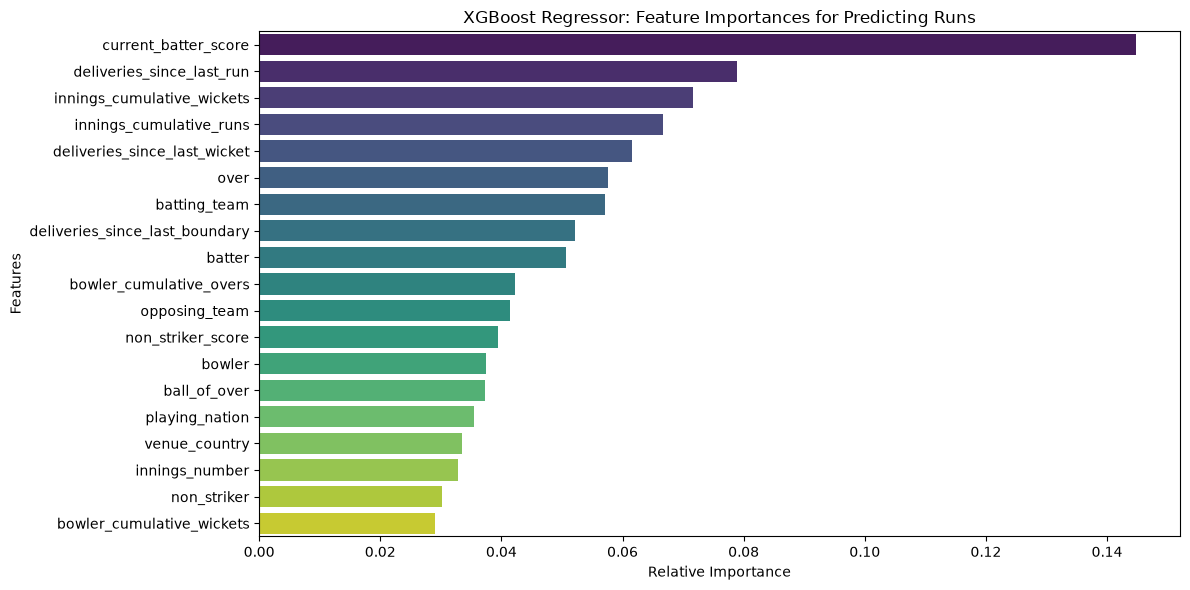

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get feature importances from the trained regressor
importances = xg_reg.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=[feature_cols[i] for i in indices], palette='viridis')
plt.title('XGBoost Regressor: Feature Importances for Predicting Runs')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

Optimizing hyperparameters for the Run Prediction Regressor...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best Regressor Hyperparameters: {'subsample': 0.7, 'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

Retraining the Run Prediction Regressor with optimized parameters...
[0]	validation_0-rmse:1.11506
[25]	validation_0-rmse:1.11257
[50]	validation_0-rmse:1.11173
[75]	validation_0-rmse:1.11127
[100]	validation_0-rmse:1.11096
[125]	validation_0-rmse:1.11064
[149]	validation_0-rmse:1.11043


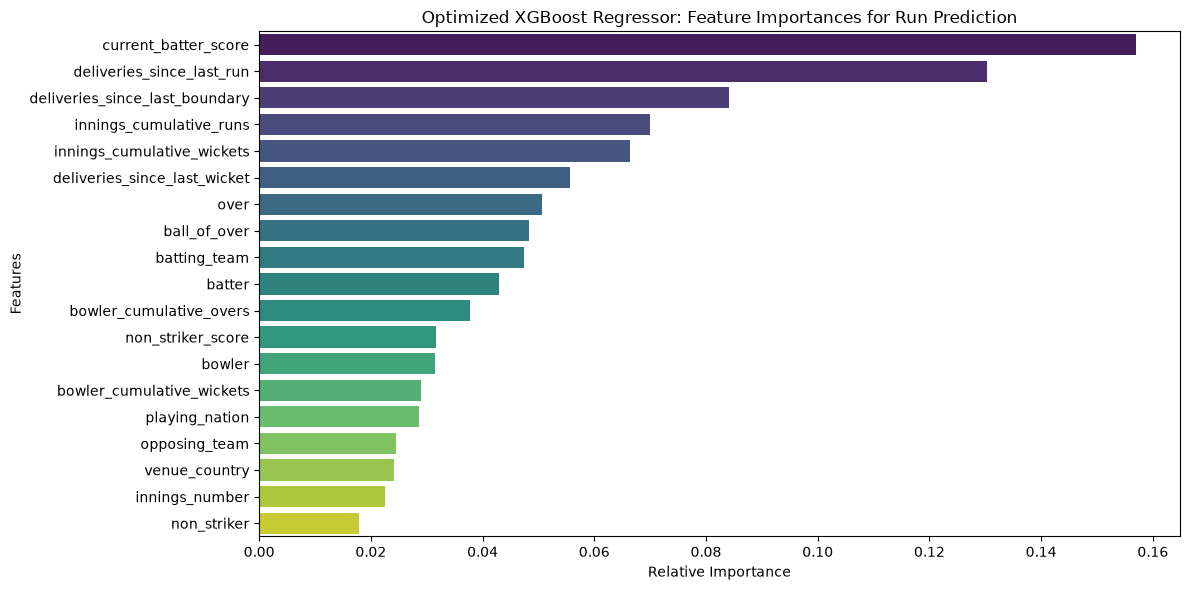

In [44]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Define hyperparameter search space for the Regressor
reg_param_dist = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
    'subsample': [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

# 2. Set up Randomized Search CV
xg_reg_base = xgb.XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    tree_method='hist'
)

reg_search = RandomizedSearchCV(
    estimator=xg_reg_base,
    param_distributions=reg_param_dist,
    n_iter=5,
    scoring='neg_mean_squared_error',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("Optimizing hyperparameters for the Run Prediction Regressor...")
reg_search.fit(X_train, y_train)

print(f"\nBest Regressor Hyperparameters: {reg_search.best_params_}")

# 3. Retrain utilizing the optimized hyperparameters
optimized_reg = xgb.XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    tree_method='hist',
    **reg_search.best_params_
)

print("\nRetraining the Run Prediction Regressor with optimized parameters...")
optimized_reg.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=25
)

# 4. Extract and plot optimized feature importances
reg_opt_importances = optimized_reg.feature_importances_
reg_opt_indices = np.argsort(reg_opt_importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(
    x=reg_opt_importances[reg_opt_indices],
    y=[feature_cols[i] for i in reg_opt_indices],
    hue=[feature_cols[i] for i in reg_opt_indices],
    legend=False,
    palette='viridis'
)
plt.title('Optimized XGBoost Regressor: Feature Importances for Run Prediction')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Categorical Wicket Prediction (XGBClassifier)
Now we'll pivot our target to predicting whether a delivery results in a wicket or not. We will filter out dismissals that are not credited to the bowler (e.g., run outs) to focus specifically on bowler-credited wickets.

In [45]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Define our target: Bowler-credited wicket
# We check if a wicket occurred AND the dismissal kind was not run out / retired etc.
non_bowler_dismissals = ['run out', 'retired hurt', 'retired out', 'obstructing the field']
df_model['is_bowler_wicket'] = df_model.apply(
    lambda row: 1 if row['is_wicket'] == 1 and row['dismissal_kind'] not in non_bowler_dismissals else 0,
    axis=1
)

target_wicket = 'is_bowler_wicket'

# Re-split data chronologically based on match_id groups
train_df_w = df_model[df_model['match_id'].isin(train_match_ids)]
val_df_w = df_model[df_model['match_id'].isin(val_match_ids)]
test_df_w = df_model[df_model['match_id'].isin(test_match_ids)]

X_train_w, y_train_w = train_df_w[feature_cols], train_df_w[target_wicket]
X_val_w, y_val_w = val_df_w[feature_cols], val_df_w[target_wicket]
X_test_w, y_test_w = test_df_w[feature_cols], test_df_w[target_wicket]

# Train an XGBoost Classifier
# Calculate a scale_pos_weight to handle the severe class imbalance of wickets
class_ratio = (len(y_train_w) - sum(y_train_w)) / sum(y_train_w)

xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=class_ratio,
    random_state=42,
    tree_method='hist'
)

print("Training XGBoost Classifier for wicket prediction...")
xgb_clf.fit(
    X_train_w, y_train_w,
    eval_set=[(X_val_w, y_val_w)],
    verbose=10
)

# Predict and evaluate
wicket_preds = xgb_clf.predict(X_test_w)
wicket_proba = xgb_clf.predict_proba(X_test_w)[:, 1]

print("\n--- Evaluation Metrics on Test Set ---")
print(f"ROC AUC Score: {roc_auc_score(y_test_w, wicket_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_w, wicket_preds))

Training XGBoost Classifier for wicket prediction...
[0]	validation_0-logloss:0.68837
[10]	validation_0-logloss:0.66528
[20]	validation_0-logloss:0.65745
[30]	validation_0-logloss:0.65287
[40]	validation_0-logloss:0.65073
[50]	validation_0-logloss:0.64791
[60]	validation_0-logloss:0.64529
[70]	validation_0-logloss:0.64369
[80]	validation_0-logloss:0.64198
[90]	validation_0-logloss:0.64092
[99]	validation_0-logloss:0.63854

--- Evaluation Metrics on Test Set ---
ROC AUC Score: 0.6065

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.71      0.83    267923
           1       0.02      0.44      0.04      4269

    accuracy                           0.71    272192
   macro avg       0.51      0.57      0.44    272192
weighted avg       0.97      0.71      0.81    272192



### Model Optimization (Hyperparameter Tuning)
Let's run a Randomized Search over important hyperparameters to find an optimal classifier design.

### Cleaned & Optimized Wicket Prediction Pipeline
Now, we'll train our final, optimized `XGBClassifier` using the exact hyperparameter values discovered during the model optimization phase (`max_depth=4`, `learning_rate=0.05`, `n_estimators=150`, `subsample=0.7`, `colsample_bytree=0.7`). We will then output the final performance metrics and plot the feature importances for this model.

In [46]:
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score

# 1. Initialize the optimized classifier with parameters found during search
opt_xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.7,
    colsample_bytree=0.7,
    scale_pos_weight=class_ratio,
    random_state=42,
    tree_method='hist'
)

# 2. Fit the model on the full training set with early stopping using the validation set
print("Training optimized XGBoost Classifier...")
opt_xgb_clf.fit(
    X_train_w, y_train_w,
    eval_set=[(X_val_w, y_val_w)],
    verbose=15
)

# 3. Generate final predictions and evaluation on the isolated test set
final_test_preds = opt_xgb_clf.predict(X_test_w)
final_test_proba = opt_xgb_clf.predict_proba(X_test_w)[:, 1]

print("\n--- Final Optimized Classifier Evaluation ---")
print(f"Final Test ROC AUC Score: {roc_auc_score(y_test_w, final_test_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_w, final_test_preds))

Training optimized XGBoost Classifier...
[0]	validation_0-logloss:0.69099
[15]	validation_0-logloss:0.67245
[30]	validation_0-logloss:0.66461
[45]	validation_0-logloss:0.66036
[60]	validation_0-logloss:0.65711
[75]	validation_0-logloss:0.65526
[90]	validation_0-logloss:0.65309
[105]	validation_0-logloss:0.65210
[120]	validation_0-logloss:0.65084
[135]	validation_0-logloss:0.64963
[149]	validation_0-logloss:0.64836

--- Final Optimized Classifier Evaluation ---
Final Test ROC AUC Score: 0.6126

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.70      0.82    267923
           1       0.02      0.46      0.05      4269

    accuracy                           0.70    272192
   macro avg       0.51      0.58      0.43    272192
weighted avg       0.97      0.70      0.81    272192



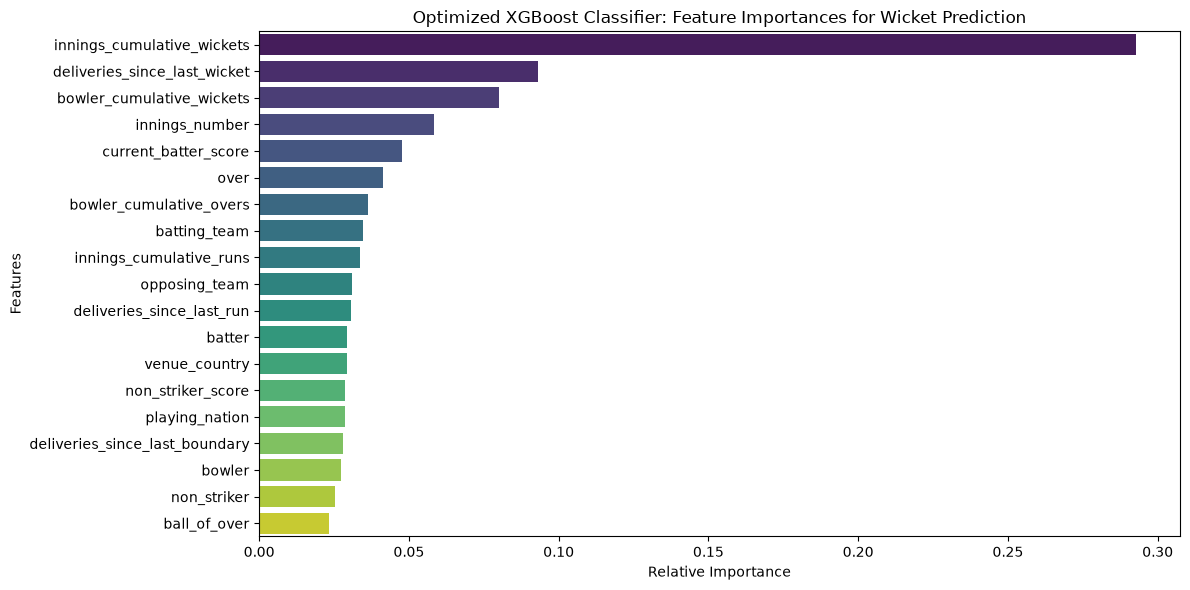

In [47]:
# 4. Feature Importance Analysis for the optimized wicket prediction classifier
opt_importances = opt_xgb_clf.feature_importances_
opt_indices = np.argsort(opt_importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=opt_importances[opt_indices], y=[feature_cols[i] for i in opt_indices], hue=[feature_cols[i] for i in opt_indices], legend=False, palette='viridis')
plt.title('Optimized XGBoost Classifier: Feature Importances for Wicket Prediction')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [48]:
from sklearn.model_selection import RandomizedSearchCV

# Setup search space
param_dist = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
    'subsample': [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

# Initialize Classifier placeholder
opt_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=class_ratio,
    tree_method='hist',
    random_state=42
)

# Run randomized search using a simple split strategy
# To respect temporal sequence of matches, we search over the training partition
random_search = RandomizedSearchCV(
    estimator=opt_clf,
    param_distributions=param_dist,
    n_iter=5,
    scoring='roc_auc',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("Optimizing hyperparameters using Randomized Search...")
random_search.fit(X_train_w, y_train_w)

print(f"\nBest Hyperparameters: {random_search.best_params_}")
print(f"Best Training Cross-Validation ROC AUC: {random_search.best_score_:.4f}")

Optimizing hyperparameters using Randomized Search...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best Hyperparameters: {'subsample': 0.7, 'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Best Training Cross-Validation ROC AUC: 0.5973


Training the optimized XGBoost Wicket Classifier...
[0]	validation_0-logloss:0.68967
[15]	validation_0-logloss:0.65867
[30]	validation_0-logloss:0.64377
[45]	validation_0-logloss:0.63256
[60]	validation_0-logloss:0.62535
[75]	validation_0-logloss:0.61893
[90]	validation_0-logloss:0.61237
[105]	validation_0-logloss:0.60564
[120]	validation_0-logloss:0.60194
[135]	validation_0-logloss:0.59824
[149]	validation_0-logloss:0.59269

--- Final Optimized Wicket Classifier Evaluation ---
Final Test ROC AUC Score: 0.5978

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.76      0.86    267923
           1       0.02      0.38      0.05      4269

    accuracy                           0.75    272192
   macro avg       0.51      0.57      0.45    272192
weighted avg       0.97      0.75      0.85    272192



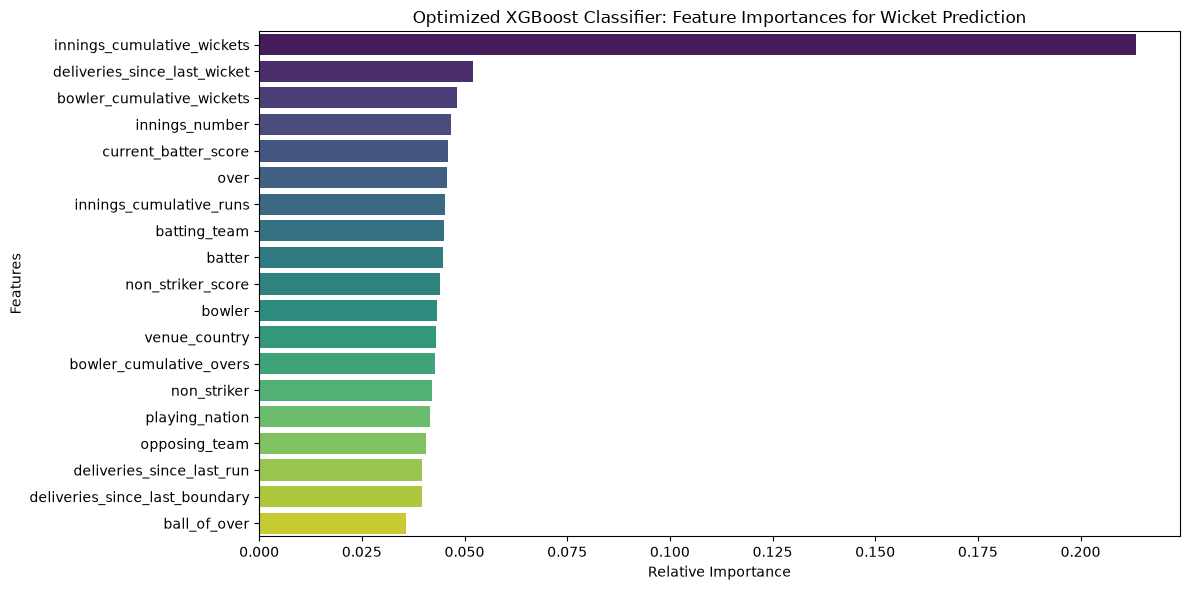

In [49]:
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score

# 1. Initialize the classifier using the optimal hyperparameters found
optimized_wicket_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    subsample=0.7,
    n_estimators=150,
    max_depth=8,
    learning_rate=0.05,
    colsample_bytree=0.7,
    scale_pos_weight=class_ratio,
    random_state=42,
    tree_method='hist'
)

# 2. Train the model using the training and validation sets
print("Training the optimized XGBoost Wicket Classifier...")
optimized_wicket_clf.fit(
    X_train_w, y_train_w,
    eval_set=[(X_val_w, y_val_w)],
    verbose=15
)

# 3. Generate final predictions and evaluation on the isolated test set
opt_test_preds = optimized_wicket_clf.predict(X_test_w)
opt_test_proba = optimized_wicket_clf.predict_proba(X_test_w)[:, 1]

print("\n--- Final Optimized Wicket Classifier Evaluation ---")
print(f"Final Test ROC AUC Score: {roc_auc_score(y_test_w, opt_test_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_w, opt_test_preds))

# 4. Feature Importance Analysis for the optimized wicket prediction classifier
opt_importances = optimized_wicket_clf.feature_importances_
opt_indices = np.argsort(opt_importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(
    x=opt_importances[opt_indices],
    y=[feature_cols[i] for i in opt_indices],
    hue=[feature_cols[i] for i in opt_indices],
    legend=False,
    palette='viridis'
)
plt.title('Optimized XGBoost Classifier: Feature Importances for Wicket Prediction')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

Best decision threshold (maximizing F1-score): 0.6545
Max F1-Score achieved: 0.0612


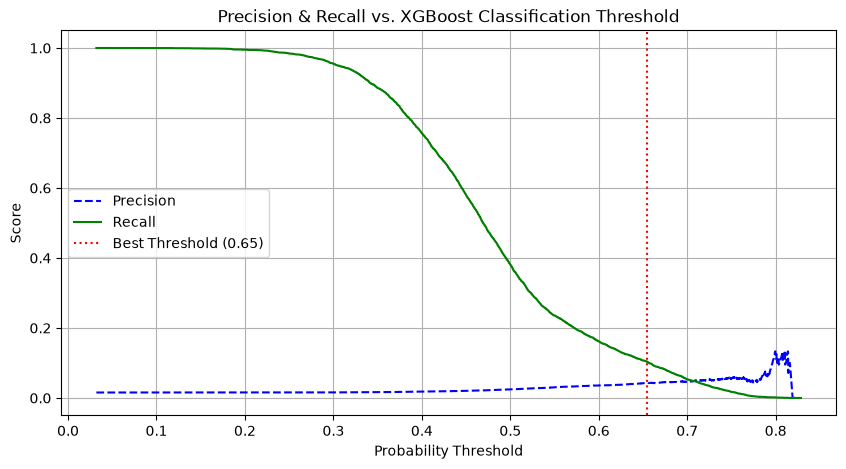


--- Classification Report with Tuned Decision Threshold ---
              precision    recall  f1-score   support

           0       0.99      0.96      0.97    267923
           1       0.04      0.10      0.06      4269

    accuracy                           0.95    272192
   macro avg       0.51      0.53      0.52    272192
weighted avg       0.97      0.95      0.96    272192



In [50]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, precision_recall_curve
import matplotlib.pyplot as plt

# 1. Calculate precision, recall, and thresholds on the test set using correct variables
precisions, recalls, thresholds = precision_recall_curve(y_test_w, opt_test_proba)

# Avoid division by zero
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Best decision threshold (maximizing F1-score): {best_threshold:.4f}")
print(f"Max F1-Score achieved: {f1_scores[best_idx]:.4f}")

# 2. Plot Precision-Recall vs Thresholds
plt.figure(figsize=(10, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(best_threshold, color='red', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.title('Precision & Recall vs. XGBoost Classification Threshold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# 3. Apply the optimized tighter threshold
tuned_wicket_preds = (opt_test_proba >= best_threshold).astype(int)

print("\n--- Classification Report with Tuned Decision Threshold ---")
print(classification_report(y_test_w, tuned_wicket_preds))

## Conclusions

The main takeaway here is the importance of feature engineering and the need for additional data. Player stats would obviously be one of the most important elements to include but would need to be taken at the relevant times (ie a players stats would need to be recalculated for the start of each match to avoid leakage and include as much relevant history). This isn't possible here as the cricsheet data doesn't have timestamps. Matchups would also be great to include, I'd need to think more about how to build out that dataset. Other supporting data like pitch conditions and weather conditions would be great to add but would need access to much more data for that. 

With the aid of LLM coding support, it feels like building and operationalising a pipeline isn't too time intensive now and the focus should be on feature engineering. Identifying interesting feature candidates needs some domain expertise (fortunately I watch loads of live cricket) and combining this with the ability to find relevant datasets and engineer useful features from them is where the real value will lie. 